In [38]:
from dotenv import load_dotenv
load_dotenv()

from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-5.4-mini", stream_usage=True,temperature=0.7)


In [39]:
from pydantic import BaseModel,Field
from typing import List,Literal
from langchain_core.prompts import ChatPromptTemplate
from typing import TypedDict


class llm_schema(BaseModel):
    funny_flag:Literal['funny','not funny']=Field(description="Whether the joke is funny or not funny")
    feedback:str=Field(description="Feedback on the joke")



llm_with_schema=llm.with_structured_output(llm_schema)



In [40]:
class graph_schema(TypedDict):

    topic:str
    joke:str
    funny_flag:str
    feedback:str
    max_iteration:int

In [41]:
def generate_node(state:graph_schema)->graph_schema:

    topic=state['topic']
    joke=state['joke']
    
    if state['feedback']:
        response=llm.invoke(f"please modify thefollowing joke {joke} based on the following feedback {state['feedback']}")
    else:
        response=llm.invoke(f'create a joke about teh following topic {topic}')

    state['joke']=response.content
    return state



In [42]:
def evaluate_node(state: graph_schema) -> dict:
    joke = state["joke"]
    iteration = state["max_iteration"]

    prompt = ChatPromptTemplate.from_messages([
        ("system", "you are a comedy critic your job is to evaluate the following joke and provide feedback on how to make it funnier"),
        ("user", "evaluate the following joke {joke} and respond with funny or not funny and if it is not funny provide feedback about how to make it funny")
    ])

    chain = prompt | llm_with_schema
    response = chain.invoke({"joke": joke})

    return {
        "funny_flag": response.funny_flag,
        "feedback": response.feedback,
        "max_iteration": iteration + 1,
    }

In [43]:
def check_iteration(state:graph_schema)->graph_schema:

    iteration=state['max_iteration']

    if iteration <=5:
        return 'evaluate_node'
    else:
        return 'end'



In [44]:
from langgraph.graph import StateGraph, START, END

graph=StateGraph(graph_schema)

graph.add_node("generate_node",generate_node)
graph.add_node("evaluate_node",evaluate_node)


graph.add_edge(START,'generate_node')
graph.add_conditional_edges('generate_node',check_iteration,{'evaluate_node':'evaluate_node','end':END})
graph.add_edge("evaluate_node","generate_node")
graph.add_edge("generate_node",END)

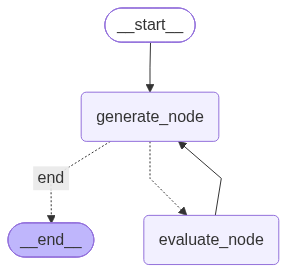

In [45]:
from IPython.display import Image, display

complex_graph=graph.compile()
Image(complex_graph.get_graph().draw_mermaid_png())

In [46]:
for chunk in complex_graph.stream(
    {
    "topic":"cars",
    "joke":"",
    "funny_flag":"",
    "feedback":"",
    "max_iteration":0
    },
    stream_mode="updates"
):
    print(chunk)

{'generate_node': {'topic': 'cars', 'joke': 'Why did the car bring a ladder?\n\nBecause it wanted to reach the high beams!', 'funny_flag': '', 'feedback': '', 'max_iteration': 0}}
{'evaluate_node': {'funny_flag': 'funny', 'feedback': 'The joke works because it plays on the double meaning of "high beams"—car headlights and something physically high. It’s a simple, clean pun. To make it funnier, you could add a little more surprise or absurdity, like giving the car a ridiculous reason for needing the ladder, or stretching the setup so the punchline feels less expected.', 'max_iteration': 1}}
{'generate_node': {'topic': 'cars', 'joke': 'Sure — here’s a funnier version with a little more surprise and absurdity:\n\n**Why did the car bring a ladder to the midnight drive?**  \n**Because it heard the high beams were too high to reach without one!**\n\nIf you want, I can also make it:\n- **more absurd**\n- **shorter and punchier**\n- **more kid-friendly**\n- **more clever/drier**', 'funny_flag'